# 🏠 House Price Project: 1 Lakh Rows, End to End

**Dataset:** `house_price_dataset_1lakh.csv` (101,200 rows × 26 columns, with deliberately messy data)

**What this notebook covers (nothing skipped):**

| Part | Steps |
|---|---|
| A. Data | Load → Inspect → Clean → EDA → Feature engineering |
| B. Regression | Split → Preprocess → 10 models → Ensemble blend → CV → Tuning → Residuals → Importance |
| C. Classification | Will it sell in 30 days? · Which price category? |
| D. Unsupervised | K-Means market segments + PCA |
| E. Time series | Price index forecast: Naive vs Holt-Winters vs ARIMA |
| F. Deploy | Save model + `predict_price()` function |

Each section says **WHAT** we do and **WHY**. Insights are printed from the real data, so they always match the numbers.

## Step 1: Imports and settings
**WHY:** Load every tool once at the top. A fixed `RANDOM_STATE` makes results reproducible (same split, same model every run).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import joblib, time, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             silhouette_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor, LGBMClassifier
from catboost import CatBoostRegressor

pd.set_option("display.max_columns", 60); pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_style("whitegrid"); plt.rcParams["figure.figsize"] = (8, 4)
RANDOM_STATE = 42

## Step 2: Load the data
**WHY:** Everything starts from raw data. We keep an untouched copy (`df_raw`) so we can always compare before vs after cleaning.

In [2]:
df_raw = pd.read_csv("house_price_dataset_1lakh.csv")
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (101200, 26)


,property_id,listing_date,city,locality,property_type,size_sqft,bedrooms,bathrooms,balconies,floor_no,total_floors,age_years,furnishing,parking_spots,lift,gym,swimming_pool,security,dist_city_center_km,dist_metro_km,facing,owner_type,builder_rating,price_lakh,price_category,sold_within_30_days
0,PRP107840,2022-09-19,Bhubaneswar,Rasulgarh,Apartment,906.00,2,2.00,0.00,25,32,7.30,Semi-Furnished,0,Yes,Yes,No,Yes,7.00,2.50,South-West,Agent,2.60,50.84,Medium,1
1,PRP151909,2022-12-08,Hyderabad,Banjara Hills,Villa,"2,189.00",4,4.00,0.00,3,3,16.00,Unfurnished,1,No,No,No,No,2.70,1.40,South,Agent,NaN,162.86,High,0
2,PRP124030,2021-05-23,Hyderabad,Madhapur,Independent House,"1,023.00",2,2.00,0.00,2,2,11.70,Semi-Furnished,2,No,No,No,Yes,5.30,3.10,West,Owner,3.40,97.10,Medium,1
3,PRP115310,2020-03-16,Chennai,Adyar,Apartment,"1,359.00",2,3.00,NaN,8,8,12.60,Semi-Furnished,1,Yes,No,No,No,5.70,1.10,South,Agent,NaN,73.19,Medium,1
4,PRP128734,2019-11-10,Ahmedabad,Gota,Apartment,"1,675.00",3,3.00,3.00,18,32,6.80,Full Furnished,1,Yes,No,No,No,8.10,4.50,South-West,Builder,NaN,106.49,Medium,1


## Step 3: Initial inspection (data audit)
**WHAT:** Look at types, missing values, duplicates, summary statistics, and category spellings.

**WHY:** You cannot clean what you have not found. This step produces the *to-do list* for cleaning.

In [3]:
print(df.dtypes.to_string())
miss = pd.DataFrame({"missing": df.isnull().sum(), "missing_%": df.isnull().mean()*100})
print("\nColumns with missing values:"); print(miss[miss.missing > 0].sort_values("missing", ascending=False))
print("\nExact duplicate rows:", df.duplicated().sum())
print("Unique property_id:", df.property_id.nunique(), "of", len(df))

property_id                str
listing_date               str
city                       str
locality                   str
property_type              str
size_sqft              float64
bedrooms                 int64
bathrooms              float64
balconies              float64
floor_no                 int64
total_floors             int64
age_years              float64
furnishing                 str
parking_spots            int64
lift                       str
gym                        str
swimming_pool              str
security                   str
dist_city_center_km    float64
dist_metro_km          float64
facing                     str
owner_type                 str
builder_rating         float64
price_lakh             float64
price_category             str
sold_within_30_days      int64

Columns with missing values:
                missing  missing_%
builder_rating    12185      12.04
facing             8227       8.13
dist_metro_km      6170       6.10
age_years          5106 

In [4]:
print("Numeric summary (look at min / max for impossible values):")
df.describe().T

Numeric summary (look at min / max for impossible values):


,count,mean,std,min,25%,50%,75%,max
size_sqft,"100,198.00","1,358.70","1,177.71",10.00,975.00,"1,243.00","1,599.00","80,000.00"
bedrooms,"101,200.00",2.46,1.15,0.00,2.00,2.00,3.00,20.00
bathrooms,"99,185.00",2.32,1.21,1.00,1.00,2.00,3.00,7.00
balconies,"98,091.00",1.50,1.12,0.00,1.00,1.00,2.00,3.00
floor_no,"101,200.00",7.69,7.90,0.00,2.00,3.00,12.00,46.00
total_floors,"101,200.00",11.33,10.76,1.00,2.00,6.00,20.00,34.00
age_years,"96,094.00",8.83,6.22,-5.00,4.40,7.50,11.80,150.00
parking_spots,"101,200.00",1.27,0.80,0.00,1.00,1.00,2.00,3.00
dist_city_center_km,"101,200.00",7.51,4.76,0.30,4.00,6.50,9.90,40.00
dist_metro_km,"95,030.00",3.99,2.82,0.10,1.90,3.40,5.40,25.00


In [5]:
# Step 1: Calculate Q1 and Q3
Q1 = df["price_lakh"].quantile(0.25)
Q3 = df["price_lakh"].quantile(0.75)

# Step 2: Calculate IQR
IQR = Q3 - Q1

# Step 3: Calculate outlier limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Step 4: Detect outliers
outliers = df[
    (df["price_lakh"] < lower_limit) |
    (df["price_lakh"] > upper_limit)
]

# Step 5: Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Outlier count:", len(outliers))
print("Outlier percentage:",
      round(len(outliers) / len(df) * 100, 2), "%")

Q1: 66.74
Q3: 168.42
IQR: 101.67999999999999
Lower limit: -85.77999999999999
Upper limit: 320.93999999999994
Outlier count: 7186
Outlier percentage: 7.1 %


In [6]:
display(outliers["price_lakh"])

22       342.57
41       575.89
44       391.35
60       583.75
85       388.86
          ...  
101110   327.67
101130   392.05
101132   397.71
101140   607.78
101159   378.19
Name: price_lakh, Length: 7186, dtype: float64

In [7]:
display(
    outliers.sort_values(
        by="price_lakh",
        ascending=False
    ).head(20)
)

,property_id,listing_date,city,locality,property_type,size_sqft,bedrooms,bathrooms,balconies,floor_no,total_floors,age_years,furnishing,parking_spots,lift,gym,swimming_pool,security,dist_city_center_km,dist_metro_km,facing,owner_type,builder_rating,price_lakh,price_category,sold_within_30_days
28945,PRP167780,2020-01-20,Delhi,Rohini,Villa,"1,854.00",3,3.00,3.00,2,2,5.90,Semi-Furnished,0,No,No,No,Yes,2.50,2.70,South,Owner,3.20,"8,888.75",High,0
45689,PRP169515,2024-06-07,Chennai,OMR,Apartment,"2,293.00",4,3.00,3.00,18,22,1.90,Fully-Furnished,2,Yes,Yes,No,Yes,14.50,5.30,East,Agent,3.10,"7,882.75",High,0
3650,PRP107757,2020-12-02,Mumbai,Powai,Apartment,"1,183.00",3,3.00,2.00,6,6,6.50,Fully-Furnished,1,Yes,Yes,No,Yes,13.40,NaN,North,Agent,4.30,"7,718.25",High,0
11481,PRP199087,2020-08-07,Delhi,Janakpuri,Independent House,"1,172.00",2,1.00,1.00,3,3,6.30,Semi-Furnished,2,No,No,No,No,3.60,4.10,North-East,Agent,4.00,"5,514.25",High,0
53145,PRP108353,2023-08-11,Delhi,Noida Ext,Independent House,"1,253.00",1,1.00,3.00,3,3,10.70,Semi-Furnished,1,No,Yes,No,No,3.60,0.80,East,Agent,4.50,"5,370.50",High,0
70420,PRP165434,2025-04-08,Bengaluru,Indiranagar,Apartment,"1,519.00",3,3.00,0.00,29,29,3.60,Semi-Furnished,1,Yes,Yes,No,Yes,1.40,2.90,North,Owner,4.70,"4,805.50",High,1
72719,PRP118210,2022-05-14,Delhi,Janakpuri,Apartment,906.00,2,2.00,0.00,15,20,7.30,Unfurnished,1,Yes,Yes,No,Yes,5.20,4.40,South,Owner,4.10,"4,795.25",High,1
46915,PRP127560,2019-06-14,Bengaluru,Indiranagar,Apartment,"2,126.00",4,5.00,1.00,26,26,14.50,Semi-Furnished,0,Yes,No,No,Yes,7.10,1.80,North-East,Agent,5.00,"4,702.25",High,0
8422,PRP102461,2025-06-26,Kolkata,Garia,Apartment,"1,820.00",4,5.00,3.00,15,15,1.80,Semi-Furnished,0,Yes,No,No,Yes,8.60,1.50,South-West,Owner,2.80,"4,632.75",High,0
47004,PRP194043,2024-02-10,Ahmedabad,Bopal,Apartment,"2,388.00",3,2.00,2.00,14,14,1.00,Semi-Furnished,3,Yes,Yes,No,Yes,13.80,1.10,South-West,Owner,4.50,"4,470.00",High,0


In [8]:
print("Total outliers:", len(outliers))
print("Minimum outlier price:", outliers["price_lakh"].min())
print("Maximum outlier price:", outliers["price_lakh"].max())

Total outliers: 7186
Minimum outlier price: 320.95
Maximum outlier price: 8888.75


In [48]:
print(outliers["price_lakh"].describe())

count   7,186.00
mean      474.73
std       285.54
min       320.95
25%       358.12
50%       413.11
75%       512.73
max     8,888.75
Name: price_lakh, dtype: float64


In [9]:
outliers.to_csv("house_price_outliers.csv", index=False)

print("Outliers saved successfully!")

Outliers saved successfully!


In [10]:
print("CITY spellings in raw data:"); print(df.city.value_counts().to_string())
print("\nFURNISHING spellings:"); print(df.furnishing.value_counts(dropna=False).to_string())
print("\nPROPERTY TYPE spellings:"); print(df.property_type.value_counts().to_string())

CITY spellings in raw data:
city
Bengaluru       10703
Hyderabad       10126
Pune            10024
Delhi            9757
Bhubaneswar      9728
Chennai          9139
Cuttack          8991
Mumbai           8821
Ahmedabad        8127
Kolkata          8073
CUTTACK           605
Calcutta          600
kolkata           573
cuttack           572
BANGALORE         520
delhi             481
bengaluru         476
DELHI             471
Bangalore         458
Bhubaneshwar      451
BBSR              445
bhubaneswar       436
New Delhi         419
MUMBAI            408
mumbai            402
Bombay            394

FURNISHING spellings:
furnishing
Semi-Furnished     42789
Unfurnished        34040
Fully-Furnished    18902
NaN                 4181
semi furnished       889
Full Furnished       399

PROPERTY TYPE spellings:
property_type
Apartment            53893
Builder Floor        19728
Independent House    17631
Villa                 6938
apartment             1641
builder floor          586
independe

**Audit findings (cleaning to-do list):**
1. Exact duplicate rows → drop
2. City, furnishing and property-type spelling variants → standardise
3. Impossible values: size 10 / 80000 sq.ft, bedrooms 0 / 20, negative age, floor above top floor, absurd prices
4. Missing values in 9 columns → impute sensibly
5. Missing target (`price_lakh`) → drop those rows (we never invent the answer)

## Step 4: Data cleaning
### 4.1 Remove duplicates
**WHY:** Duplicates make the model see the same house twice. If one copy lands in train and one in test, the score becomes fake-high (leakage).

In [11]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df):,} duplicates → {len(df):,} rows. property_id unique now: {df.property_id.is_unique}")

Removed 1,200 duplicates → 100,000 rows. property_id unique now: True


### 4.2 Standardise text categories
**WHY:** `Bangalore` and `Bengaluru` would become two different cities after encoding, splitting the information and confusing the model.

In [12]:
city_map = {"mumbai":"Mumbai","bombay":"Mumbai","delhi":"Delhi","new delhi":"Delhi","bengaluru":"Bengaluru","bangalore":"Bengaluru",
            "pune":"Pune","hyderabad":"Hyderabad","chennai":"Chennai","kolkata":"Kolkata","calcutta":"Kolkata",
            "ahmedabad":"Ahmedabad","bhubaneswar":"Bhubaneswar","bbsr":"Bhubaneswar","bhubaneshwar":"Bhubaneswar","cuttack":"Cuttack"}
df["city"] = df.city.str.strip().str.lower().map(city_map)

df["property_type"] = df.property_type.str.strip().str.title()

furn_map = {"unfurnished":"Unfurnished","semi-furnished":"Semi-Furnished","semi furnished":"Semi-Furnished",
            "fully-furnished":"Fully-Furnished","full furnished":"Fully-Furnished"}
df["furnishing"] = df.furnishing.str.strip().str.lower().map(furn_map)

print("Cities :", sorted(df.city.unique()), "| unmapped:", df.city.isnull().sum())
print("Types  :", sorted(df.property_type.unique()))
print("Furnish:", df.furnishing.dropna().unique())

Cities : ['Ahmedabad', 'Bengaluru', 'Bhubaneswar', 'Chennai', 'Cuttack', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai', 'Pune'] | unmapped: 0
Types  : ['Apartment', 'Builder Floor', 'Independent House', 'Villa']
Furnish: <StringArray>
['Semi-Furnished', 'Unfurnished', 'Fully-Furnished']
Length: 3, dtype: str


### 4.3 Fix impossible values
**WHY:** A 10 sq.ft house or −5 year old building is a data-entry error. Trees can ignore it, but linear models get dragged badly. We mark them missing (NaN) and impute in the next step instead of deleting the rest of the row.

In [13]:
bad = {
 "size_sqft": (~df.size_sqft.between(300, 15000) & df.size_sqft.notna()).sum(),
 "bedrooms":  (~df.bedrooms.between(1, 7)).sum(),
 "age_years": (~df.age_years.between(0, 100) & df.age_years.notna()).sum(),
 "floor_no > total_floors": (df.floor_no > df.total_floors).sum(),
}
print("Invalid values found:", bad)

df.loc[~df.size_sqft.between(300, 15000), "size_sqft"] = np.nan
df.loc[~df.bedrooms.between(1, 7), "bedrooms"] = np.nan
df.loc[~df.age_years.between(0, 100), "age_years"] = np.nan
bad_floor = df.floor_no > df.total_floors
df.loc[bad_floor, "floor_no"] = df.loc[bad_floor, "total_floors"]     # cap at top floor

Invalid values found: {'size_sqft': np.int64(60), 'bedrooms': np.int64(40), 'age_years': np.int64(50), 'floor_no > total_floors': np.int64(30)}


### 4.4 Handle missing values
**WHY:** Most models crash on NaN. We use *group medians* (e.g. metro distance by city) instead of one global number because it is closer to the truth. We also add a flag `rating_missing`, since *a rating being absent* can itself be informative.

In [14]:
# the target must never be imputed
n0 = len(df); df = df.dropna(subset=["price_lakh"]).reset_index(drop=True)
print(f"Dropped {n0-len(df)} rows with missing target")

df["rating_missing"] = df.builder_rating.isna().astype(int)

df["size_sqft"] = df.size_sqft.fillna(df.groupby(["city","property_type"]).size_sqft.transform("median"))
df["bedrooms"]  = df.bedrooms.fillna((df.size_sqft/550).round().clip(1, 7))      # bedrooms follow size
df["bathrooms"] = df.bathrooms.fillna(df.groupby("bedrooms").bathrooms.transform("median")).round()
df["balconies"] = df.balconies.fillna(df.balconies.median())
df["age_years"] = df.age_years.fillna(df.groupby("property_type").age_years.transform("median"))
df["dist_metro_km"]  = df.dist_metro_km.fillna(df.groupby("city").dist_metro_km.transform("median"))
df["builder_rating"] = df.builder_rating.fillna(df.groupby("city").builder_rating.transform("median"))
df["furnishing"] = df.furnishing.fillna(df.furnishing.mode()[0])
df["facing"]     = df.facing.fillna("Unknown")

print("Missing values left:", int(df.isnull().sum().sum()))

Dropped 513 rows with missing target
Missing values left: 0


*Note: for simplicity the medians are computed on the whole data. In strict production code you compute them on the training set only. With <12% missing and stable medians the effect here is tiny.*

### 4.5 Detect wrong prices (outlier handling)
**WHAT:** Compare each house's price per sq.ft with its **city median**. A ratio far from 1 means a typo (₹0.5 lakh or ₹5000 lakh).

**WHY:** Outliers in the *target* are the most damaging: the model tries to fit them. We remove only clear errors, not genuine luxury homes (a Mumbai villa is expensive but its ratio stays reasonable).

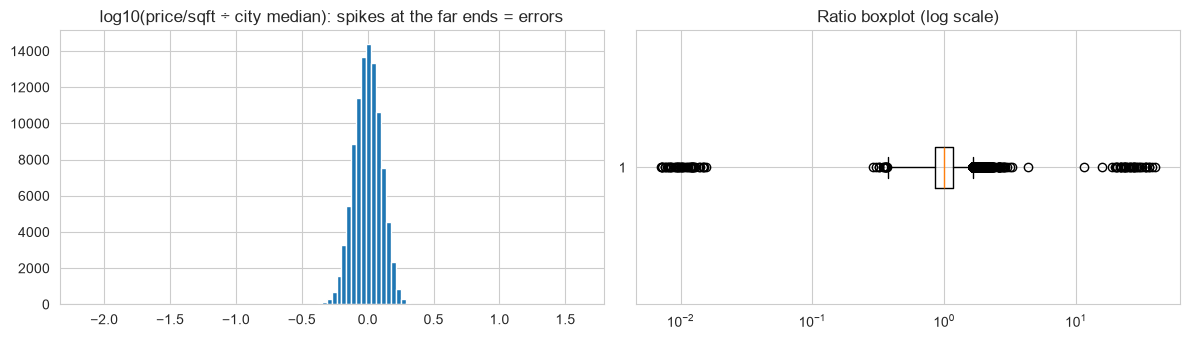

Removing 82 rows with clearly wrong prices (0.08%)
Clean shape: (99405, 29)


In [15]:
df["price_per_sqft"] = df.price_lakh / df.size_sqft                     # lakh per sqft
df["ppsf_ratio"] = df.price_per_sqft / df.groupby("city").price_per_sqft.transform("median")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(np.log10(df.ppsf_ratio), bins=100); ax[0].set_title("log10(price/sqft ÷ city median): spikes at the far ends = errors")
ax[1].boxplot(df.ppsf_ratio, vert=False); ax[1].set_xscale("log"); ax[1].set_title("Ratio boxplot (log scale)")
plt.tight_layout(); plt.show()

mask = df.ppsf_ratio.between(0.3, 3.5)
print(f"Removing {(~mask).sum()} rows with clearly wrong prices ({(~mask).mean()*100:.2f}%)")
df = df[mask].reset_index(drop=True)
df["price_category"] = pd.cut(df.price_lakh, [0, 50, 120, np.inf], labels=["Low","Medium","High"])  # recompute from clean price
df["listing_date"] = pd.to_datetime(df.listing_date)
print("Clean shape:", df.shape)

In [16]:
print(f"Rows kept: {len(df):,} of {len(df_raw):,} raw ({len(df)/len(df_raw)*100:.1f}%)")
df.describe().T[["min","50%","max"]]

Rows kept: 99,405 of 101,200 raw (98.2%)


,min,50%,max
listing_date,2019-01-01 00:00:00,2022-07-01 00:00:00,2025-12-29 00:00:00
size_sqft,350.00,"1,238.00","6,616.00"
bedrooms,1.00,2.00,7.00
bathrooms,1.00,2.00,7.00
balconies,0.00,1.00,3.00
floor_no,0.00,3.00,34.00
total_floors,1.00,6.00,34.00
age_years,0.00,7.50,45.00
parking_spots,0.00,1.00,3.00
dist_city_center_km,0.30,6.50,40.00


## Step 5: Exploratory Data Analysis (EDA)
**WHY:** EDA tells you *what drives price* before any modelling. It decides which features to engineer, which models to expect to win, and gives business insights on its own.

### 5.1 Target distribution

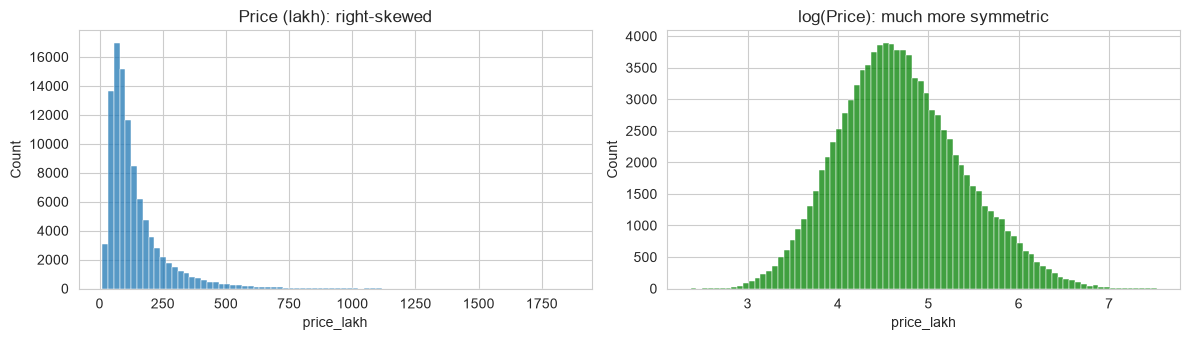

Skewness raw = 2.84, after log = 0.30
→ Insight: price is skewed, so we will model log(price). Errors then become percentage-like.


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df.price_lakh, bins=80, ax=ax[0]); ax[0].set_title("Price (lakh): right-skewed")
sns.histplot(np.log1p(df.price_lakh), bins=80, ax=ax[1], color="green"); ax[1].set_title("log(Price): much more symmetric")
plt.tight_layout(); plt.show()
print(f"Skewness raw = {df.price_lakh.skew():.2f}, after log = {np.log1p(df.price_lakh).skew():.2f}")
print("→ Insight: price is skewed, so we will model log(price). Errors then become percentage-like.")

### 5.2 Location effect

             median_price_lakh  median_ppsf_rs  listings
city                                                    
Mumbai                  325.00       26,513.00      9860
Delhi                   193.00       15,678.00     10919
Bengaluru               124.00       10,006.00     11931
Pune                    112.00        9,095.00      9873
Chennai                 107.00        8,595.00      8989
Hyderabad               102.00        8,298.00      9942
Kolkata                  83.00        6,726.00      9047
Ahmedabad                69.00        5,535.00      7992
Bhubaneswar              66.00        5,370.00     10866
Cuttack                  47.00        3,808.00      9986


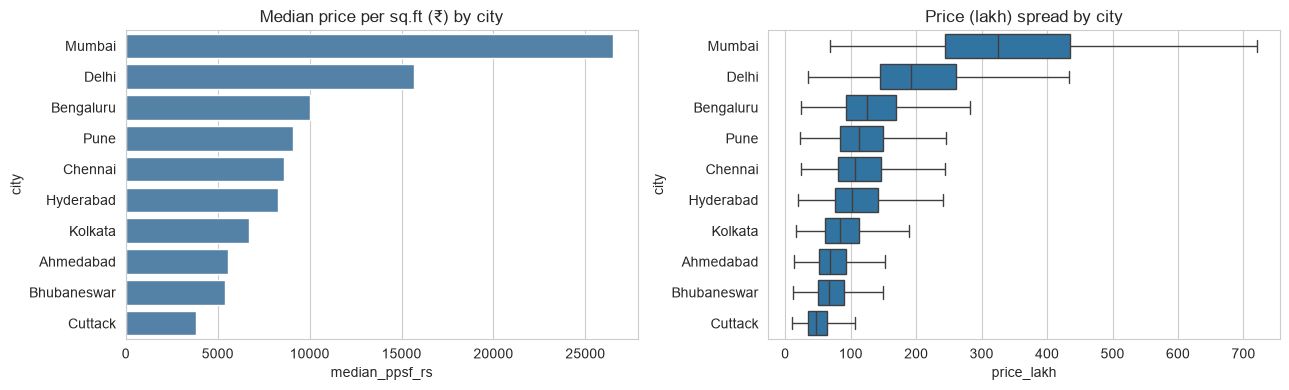

→ Insight: Mumbai costs 7.0x more per sq.ft than Cuttack. City is a top price driver.


In [18]:
city_stats = df.groupby("city").agg(median_price_lakh=("price_lakh","median"),
                                    median_ppsf_rs=("price_per_sqft", lambda s: s.median()*1e5),
                                    listings=("price_lakh","size")).sort_values("median_ppsf_rs", ascending=False)
print(city_stats.round(0).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = city_stats.index
sns.barplot(x=city_stats.median_ppsf_rs, y=order, ax=ax[0], color="steelblue"); ax[0].set_title("Median price per sq.ft (₹) by city")
sns.boxplot(data=df, y="city", x="price_lakh", order=order, ax=ax[1], showfliers=False); ax[1].set_title("Price (lakh) spread by city")
plt.tight_layout(); plt.show()
r = city_stats.median_ppsf_rs
print(f"→ Insight: {r.index[0]} costs {r.iloc[0]/r.iloc[-1]:.1f}x more per sq.ft than {r.index[-1]}. City is a top price driver.")

### 5.3 Size, bedrooms, property type

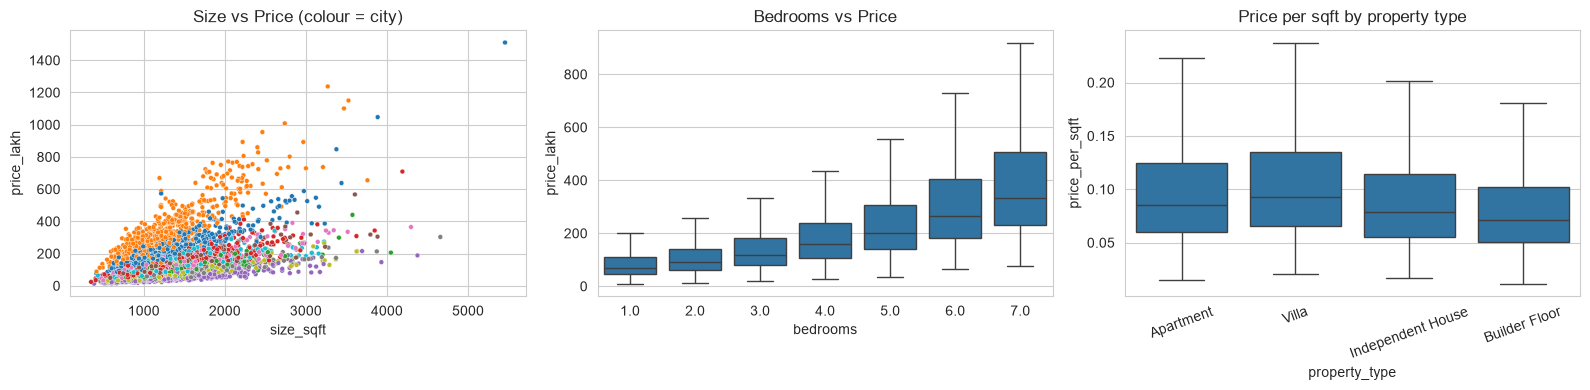

Correlation size vs price = 0.493; bedrooms vs size = 0.815
→ Insight: size is the strongest numeric driver; the cloud fans out because each city has its own rate.
→ Bedrooms and size are highly correlated (multicollinearity); regularised or tree models handle this.


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
s = df.sample(5000, random_state=1)
sns.scatterplot(data=s, x="size_sqft", y="price_lakh", hue="city", s=12, ax=ax[0], legend=False); ax[0].set_title("Size vs Price (colour = city)")
sns.boxplot(data=df, x="bedrooms", y="price_lakh", ax=ax[1], showfliers=False); ax[1].set_title("Bedrooms vs Price")
sns.boxplot(data=df, x="property_type", y="price_per_sqft", ax=ax[2], showfliers=False); ax[2].set_title("Price per sqft by property type")
plt.setp(ax[2].get_xticklabels(), rotation=20); plt.tight_layout(); plt.show()
print(f"Correlation size vs price = {df.size_sqft.corr(df.price_lakh):.3f}; bedrooms vs size = {df.bedrooms.corr(df.size_sqft):.3f}")
print("→ Insight: size is the strongest numeric driver; the cloud fans out because each city has its own rate.")
print("→ Bedrooms and size are highly correlated (multicollinearity); regularised or tree models handle this.")

### 5.4 Age, furnishing, amenities, distance

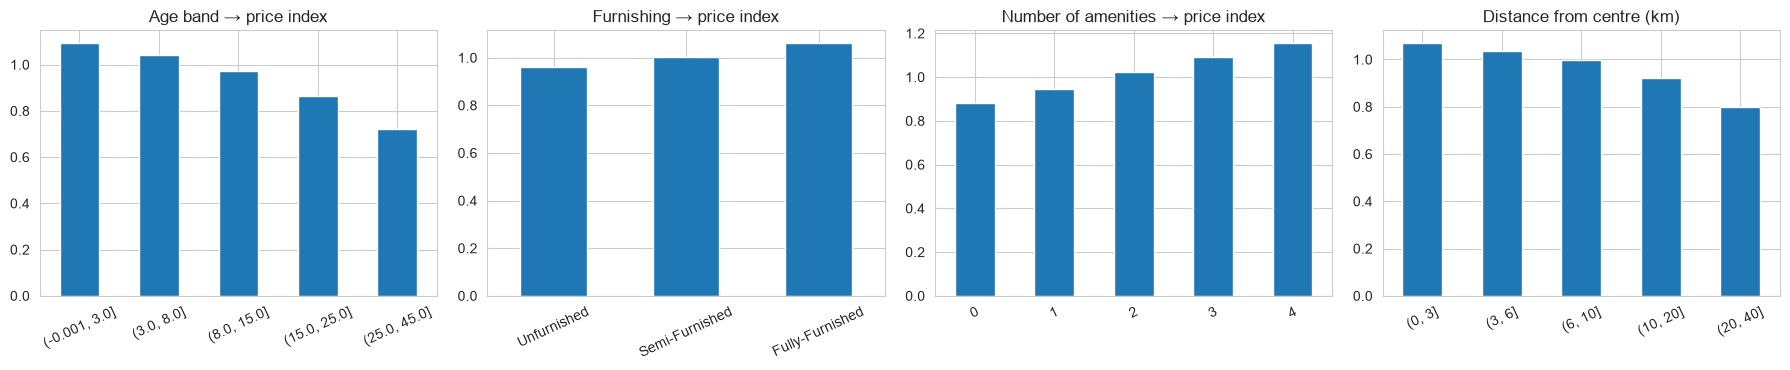

→ Insight: 4 amenities vs 0 → 31% higher price level (city-adjusted).
→ Insight: Fully-furnished vs unfurnished → 10% premium.
→ Insight: facing direction effect (spread of medians) = 0.9% → almost no effect.


In [20]:
df["_amen"] = (df[["lift","gym","swimming_pool","security"]] == "Yes").sum(axis=1)
df["_ppsf_idx"] = df.price_per_sqft / df.groupby("city").price_per_sqft.transform("median")   # city-adjusted price level

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
df.groupby(pd.cut(df.age_years,[0,3,8,15,25,45], include_lowest=True))._ppsf_idx.median().plot(kind="bar", ax=ax[0], title="Age band → price index")
df.groupby("furnishing")._ppsf_idx.median().reindex(["Unfurnished","Semi-Furnished","Fully-Furnished"]).plot(kind="bar", ax=ax[1], title="Furnishing → price index")
df.groupby("_amen")._ppsf_idx.median().plot(kind="bar", ax=ax[2], title="Number of amenities → price index")
df.groupby(pd.cut(df.dist_city_center_km,[0,3,6,10,20,40]))._ppsf_idx.median().plot(kind="bar", ax=ax[3], title="Distance from centre (km)")
for a in ax: a.set_xlabel(""); plt.setp(a.get_xticklabels(), rotation=25)
plt.tight_layout(); plt.show()

g = df.groupby("_amen")._ppsf_idx.median(); f = df.groupby("furnishing")._ppsf_idx.median()
print(f"→ Insight: 4 amenities vs 0 → {(g.loc[4]/g.loc[0]-1)*100:.0f}% higher price level (city-adjusted).")
print(f"→ Insight: Fully-furnished vs unfurnished → {(f['Fully-Furnished']/f['Unfurnished']-1)*100:.0f}% premium.")
print(f"→ Insight: facing direction effect (spread of medians) = {(df.groupby('facing')._ppsf_idx.median().max()/df.groupby('facing')._ppsf_idx.median().min()-1)*100:.1f}% → almost no effect.")

### 5.5 Price trend over time and correlation map

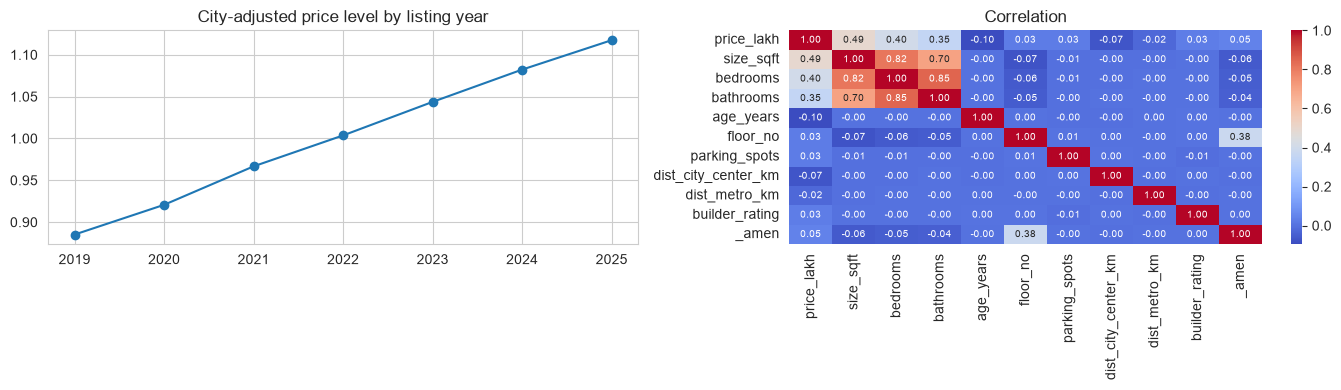

→ Insight: prices rise about 4.1% per year (2019 → 2024, ignoring the partial last year if any).


In [21]:
yearly = df.groupby(df.listing_date.dt.year)._ppsf_idx.median()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
yearly.plot(marker="o", ax=ax[0], title="City-adjusted price level by listing year"); ax[0].set_xlabel("")
num_cols = ["price_lakh","size_sqft","bedrooms","bathrooms","age_years","floor_no","parking_spots","dist_city_center_km","dist_metro_km","builder_rating","_amen"]
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], annot_kws={"size":7}); ax[1].set_title("Correlation")
plt.tight_layout(); plt.show()
cagr = (yearly.iloc[-2]/yearly.iloc[0])**(1/(len(yearly)-2))-1
print(f"→ Insight: prices rise about {cagr*100:.1f}% per year (2019 → 2024, ignoring the partial last year if any).")
df = df.drop(columns=["_amen","_ppsf_idx"])

## Step 6: Feature engineering
**WHAT:** Create new columns that express relationships the raw columns hide.

**WHY:** Models see numbers only. `size_per_bedroom` tells "spaciousness", `amenity_score` collapses four weak Yes/No columns into one strong one, and date parts let the model learn the price trend.

We write it as **one function** `build_features()` so exactly the same logic is used in training and in prediction (otherwise predictions break).

In [22]:
YESNO = ["lift", "gym", "swimming_pool", "security"]
FURN_ORD = {"Unfurnished": 0, "Semi-Furnished": 1, "Fully-Furnished": 2}

def build_features(d):
    d = d.copy()
    d["listing_date"] = pd.to_datetime(d["listing_date"])
    d["years_since_2019"] = (d.listing_date.dt.year - 2019) + d.listing_date.dt.dayofyear / 365
    d["month"] = d.listing_date.dt.month
    for c in YESNO: d[c + "_flag"] = (d[c] == "Yes").astype(int)
    d["amenity_score"]   = d[[c + "_flag" for c in YESNO]].sum(axis=1)
    d["floor_ratio"]     = d.floor_no / d.total_floors
    d["size_per_bedroom"] = d.size_sqft / d.bedrooms
    d["bath_per_bed"]    = d.bathrooms / d.bedrooms
    d["furnishing_ord"]  = d.furnishing.map(FURN_ORD)
    d["is_new"]          = (d.age_years <= 3).astype(int)
    return d

NUM = ["size_sqft","bedrooms","bathrooms","balconies","floor_no","total_floors","age_years","parking_spots",
       "dist_city_center_km","dist_metro_km","builder_rating","rating_missing","years_since_2019","month",
       "lift_flag","gym_flag","swimming_pool_flag","security_flag","amenity_score","floor_ratio",
       "size_per_bedroom","bath_per_bed","furnishing_ord","is_new"]
CAT = ["city","locality","property_type","facing","owner_type"]

df_fe = build_features(df)
print("Features:", len(NUM), "numeric +", len(CAT), "categorical | NaN left in features:", int(df_fe[NUM+CAT].isnull().sum().sum()))
df_fe[NUM+CAT].head(3).T

Features: 24 numeric + 5 categorical | NaN left in features: 0


,0,1,2
size_sqft,906.00,"2,189.00","1,023.00"
bedrooms,2.00,4.00,2.00
bathrooms,2.00,4.00,2.00
balconies,0.00,0.00,0.00
floor_no,25,3,2
total_floors,32,3,2
age_years,7.30,16.00,11.70
parking_spots,0,1,2
dist_city_center_km,7.00,2.70,5.30
dist_metro_km,2.50,1.40,3.10


**Deliberately excluded as features (and why):**
- `property_id`: just a label, no meaning
- `price_category`: derived from the target → **data leakage**
- `price_per_sqft`, `ppsf_ratio`: computed from the target → leakage for the price model
- `sold_within_30_days`: a different target

# Part B: Regression (predict `price_lakh`)

## Step 7: Train / test split
**WHY:** The test set is a locked exam. The model never sees it while learning, so the test score honestly estimates future performance. 80% train / 20% test.

In [23]:
X = df_fe[NUM + CAT]; y = df_fe["price_lakh"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (79524, 29) | Test: (19881, 29)


## Step 8: Preprocessing (scaling + encoding)
**WHAT:** Scale numeric columns, one-hot encode categorical columns. **Fit on train only**, then apply to test.

**WHY:** Linear models need comparable scales (sq.ft ~1000s vs bedrooms ~3). Text categories must become numbers. Fitting on train only prevents test information leaking in.

**Target transform:** we train on `log(price)`. Price is multiplicative (city × size × age...), so in log-space those effects become additive and the data becomes much easier for models.

In [24]:
pre = ColumnTransformer([("num", StandardScaler(), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
Xtr = pre.fit_transform(X_train); Xte = pre.transform(X_test)
feat_names = pre.get_feature_names_out()
ytr_log, yte_log = np.log1p(y_train), np.log1p(y_test)
print("Matrix after encoding:", Xtr.shape, "→", Xtr.shape[1], "columns")

Matrix after encoding: (79524, 108) → 108 columns


## Step 9: Train and compare 10 regression models
**WHY:** No single algorithm wins everywhere. We test the whole family from your model tree: simple linear → regularised → trees → bagging → boosting.

**Metrics (reported in real lakh units):**
- **MAE**: average error in lakh ("off by X lakh on average")
- **RMSE**: like MAE but punishes big misses
- **R²**: share of price variation explained (1 = perfect)
- **MAPE**: average % error, the easiest number to explain to a business person

In [25]:
def reg_metrics(y_true, pred_log):
    p = np.expm1(pred_log)
    return dict(MAE=mean_absolute_error(y_true, p), RMSE=np.sqrt(mean_squared_error(y_true, p)),
                R2=r2_score(y_true, p), MAPE=np.mean(np.abs(y_true - p) / y_true) * 100)

models = {
 "Linear Regression": LinearRegression(),
 "Ridge":        Ridge(alpha=1.0),
 "Lasso":        Lasso(alpha=0.0005),
 "Elastic Net":  ElasticNet(alpha=0.0005, l1_ratio=0.5),
 "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE),
 "Random Forest": RandomForestRegressor(n_estimators=80, max_depth=14, min_samples_leaf=10, max_features=0.4,
                                        max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE),
 "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE),
 "XGBoost":  XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
 "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=63, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE),
 "CatBoost": CatBoostRegressor(iterations=400, depth=6, learning_rate=0.1, verbose=0, random_seed=RANDOM_STATE),
}
rows, test_preds = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr, ytr_log); secs = time.time() - t0
    p_te = m.predict(Xte); test_preds[name] = p_te
    r = reg_metrics(y_test, p_te)
    r.update(Model=name, Train_R2=r2_score(y_train, np.expm1(m.predict(Xtr))), Seconds=secs); rows.append(r)
    print(f"{name:22s} done  MAPE={r['MAPE']:.2f}%  ({secs:.0f}s)")
results = pd.DataFrame(rows).set_index("Model")[["MAE","RMSE","R2","MAPE","Train_R2","Seconds"]].sort_values("MAE")
results

Linear Regression      done  MAPE=9.38%  (1s)
Ridge                  done  MAPE=9.38%  (0s)
Lasso                  done  MAPE=9.68%  (3s)
Elastic Net            done  MAPE=9.48%  (7s)
Decision Tree          done  MAPE=16.53%  (1s)
Random Forest          done  MAPE=13.63%  (3s)
HistGradientBoosting   done  MAPE=6.73%  (5s)
XGBoost                done  MAPE=6.73%  (2s)
LightGBM               done  MAPE=6.61%  (2s)
CatBoost               done  MAPE=6.22%  (3s)


,MAE,RMSE,R2,MAPE,Train_R2,Seconds
Model,,,,,,
CatBoost,8.67,14.70,0.98,6.22,0.98,2.89
LightGBM,9.21,16.13,0.98,6.61,0.99,2.15
XGBoost,9.42,15.98,0.98,6.73,0.99,1.64
HistGradientBoosting,9.44,16.31,0.98,6.73,0.98,5.29
Linear Regression,14.28,43.65,0.86,9.38,0.84,0.61
Ridge,14.28,43.64,0.86,9.38,0.84,0.13
Elastic Net,14.45,43.07,0.87,9.48,0.84,6.95
Lasso,14.72,43.38,0.86,9.68,0.84,2.93
Random Forest,18.32,29.81,0.94,13.63,0.94,3.12


### 9.1 Ensemble blend
**WHAT:** Average the predictions of the top 3 models.

**WHY:** Different models make *different* mistakes; averaging cancels some of them (the idea behind Ensemble Learning). It costs nothing extra because predictions already exist.

In [26]:
top3 = results.index[:3].tolist()
blend = np.mean([test_preds[n] for n in top3], axis=0)
rb = reg_metrics(y_test, blend)
print("Blend of:", top3)
print({k: round(v, 3) for k, v in rb.items()})
best_single = results.iloc[0]
print(f"\nBest single model: {results.index[0]}  MAPE = {best_single.MAPE:.2f}%   |   Blend MAPE = {rb['MAPE']:.2f}%")
print("Linear models do well because log-price is almost additive; boosting wins by learning the leftover interactions.")

Blend of: ['CatBoost', 'LightGBM', 'XGBoost']
{'MAE': 8.786, 'RMSE': np.float64(14.93), 'R2': 0.984, 'MAPE': np.float64(6.31)}

Best single model: CatBoost  MAPE = 6.22%   |   Blend MAPE = 6.31%
Linear models do well because log-price is almost additive; boosting wins by learning the leftover interactions.


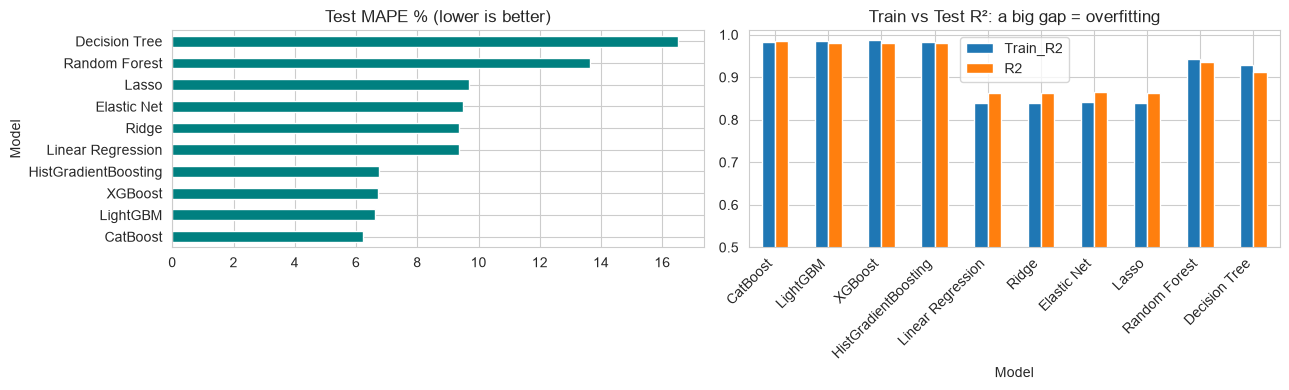

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
results.MAPE.sort_values().plot(kind="barh", ax=ax[0], color="teal", title="Test MAPE % (lower is better)")
results[["Train_R2","R2"]].plot(kind="bar", ax=ax[1], ylim=(0.5,1.01), title="Train vs Test R²: a big gap = overfitting")
plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right"); plt.tight_layout(); plt.show()

## Step 10: Hyperparameter tuning (LightGBM)
**WHAT:** Try random combinations of settings using cross-validation on a 30k sample (fast), keep the best.

**WHY:** Defaults are rarely optimal. `num_leaves`, `learning_rate` and `min_child_samples` control the fit/overfit balance. Random search covers the space much faster than a full grid.

In [28]:
param_dist = {"n_estimators": [300, 500, 800], "learning_rate": [0.03, 0.05, 0.1], "num_leaves": [31, 63, 127],
              "min_child_samples": [10, 20, 50], "subsample": [0.7, 0.9, 1.0], "colsample_bytree": [0.6, 0.8, 1.0],
              "subsample_freq": [1]}
idx = np.random.RandomState(0).choice(len(Xtr), 30000, replace=False)
search = RandomizedSearchCV(LGBMRegressor(n_jobs=-1, verbose=-1, random_state=RANDOM_STATE), param_dist, n_iter=8, cv=3,
                            scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
t0 = time.time(); search.fit(Xtr[idx], ytr_log.values[idx])
print("Best params:", search.best_params_, f"| search time {time.time()-t0:.0f}s")

Best params: {'subsample_freq': 1, 'subsample': 0.7, 'num_leaves': 31, 'n_estimators': 800, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.6} | search time 27s


In [29]:
best_lgbm = LGBMRegressor(**search.best_params_, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE).fit(Xtr, ytr_log)
pt = best_lgbm.predict(Xte); rt = reg_metrics(y_test, pt)
print("Tuned LightGBM on full train →", {k: round(v, 3) for k, v in rt.items()})
print(f"Before tuning MAPE = {results.loc['LightGBM','MAPE']:.2f}%  | after = {rt['MAPE']:.2f}%")

Tuned LightGBM on full train → {'MAE': 9.05, 'RMSE': np.float64(15.794), 'R2': 0.982, 'MAPE': np.float64(6.479)}
Before tuning MAPE = 6.61%  | after = 6.48%


## Step 11: Cross-validation of the final pipeline
**WHAT:** Re-train 5 times on different splits using the *full pipeline* (preprocessing + model inside each fold).

**WHY:** One train/test split can be lucky. 5-fold CV shows the score *and its stability*. Putting preprocessing inside the pipeline stops leakage in every fold.

In [30]:
final_model = TransformedTargetRegressor(
    regressor=Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), NUM),
                                                   ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])),
                        ("model", LGBMRegressor(**search.best_params_, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE))]),
    func=np.log1p, inverse_func=np.expm1)

cv_mae = -cross_val_score(final_model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")
cv_r2  = cross_val_score(final_model, X_train, y_train, cv=5, scoring="r2")
print("CV MAE per fold (lakh):", cv_mae.round(2), f"→ mean {cv_mae.mean():.2f} ± {cv_mae.std():.2f}")
print("CV R2  per fold       :", cv_r2.round(4),  f"→ mean {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print("Tiny spread across folds = stable, trustworthy model.")

CV MAE per fold (lakh): [9.09 9.36 9.22 8.95 9.1 ] → mean 9.14 ± 0.14
CV R2  per fold       : [0.9792 0.9802 0.9806 0.9798 0.9805] → mean 0.9801 ± 0.0005
Tiny spread across folds = stable, trustworthy model.


## Step 12: Final test evaluation + residual analysis
**WHY:** One number hides patterns. Residuals (actual − predicted) show *where* the model is weak: certain cities, price ranges, or systematic bias. Healthy residuals look like random noise around 0.

FINAL TEST → MAE 9.05 lakh | RMSE 15.79 | R2 0.9820 | MAPE 6.48%
Median absolute % error = 5.33%   | 90% of predictions are within ±13.1%


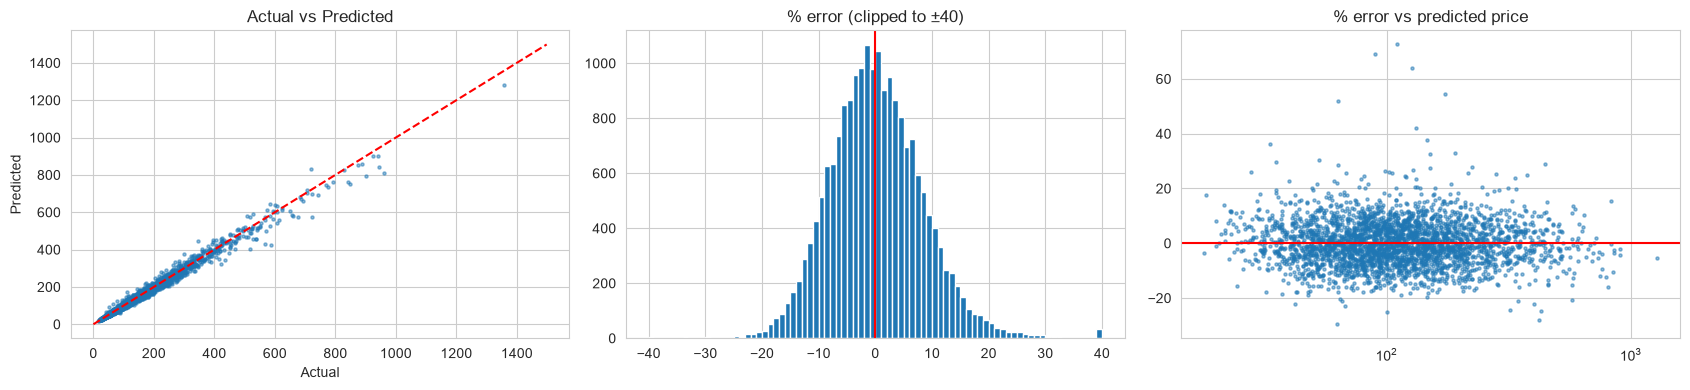

In [31]:
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)
pct_err = (pred - y_test) / y_test * 100
print(f"FINAL TEST → MAE {mean_absolute_error(y_test,pred):.2f} lakh | RMSE {np.sqrt(mean_squared_error(y_test,pred)):.2f} | "
      f"R2 {r2_score(y_test,pred):.4f} | MAPE {np.abs(pct_err).mean():.2f}%")
print(f"Median absolute % error = {np.abs(pct_err).median():.2f}%   | 90% of predictions are within ±{np.percentile(np.abs(pct_err),90):.1f}%")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ii = np.random.RandomState(1).choice(len(y_test), 3000, replace=False)
ax[0].scatter(y_test.values[ii], pred[ii], s=5, alpha=.5); lim = [0, y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs Predicted")
ax[1].hist(pct_err.clip(-40, 40), bins=80); ax[1].axvline(0, color="r"); ax[1].set_title("% error (clipped to ±40)")
ax[2].scatter(pred[ii], pct_err.values[ii], s=5, alpha=.5); ax[2].axhline(0, color="r"); ax[2].set_xscale("log")
ax[2].set_title("% error vs predicted price"); plt.tight_layout(); plt.show()

In [32]:
err = pd.DataFrame({"city": X_test.city.values, "ape": np.abs(pct_err.values), "bias": pct_err.values, "price": y_test.values})
by_city = err.groupby("city").agg(MAPE=("ape","mean"), bias_pct=("bias","mean")).sort_values("MAPE")
print(by_city.round(2).to_string())
band = err.groupby(pd.qcut(err.price, 4, labels=["Cheapest 25%","Q2","Q3","Costliest 25%"])).ape.mean()
print("\nMAPE by price band:"); print(band.round(2).to_string())
print(f"\n→ Insight: hardest city = {by_city.index[-1]} ({by_city.MAPE.iloc[-1]:.1f}% error); easiest = {by_city.index[0]} ({by_city.MAPE.iloc[0]:.1f}%).")
print("→ Bias near 0 for every city means the model does not systematically over- or under-price any market.")

             MAPE  bias_pct
city                       
Delhi        6.27     -0.30
Kolkata      6.39      0.55
Mumbai       6.39     -0.06
Bhubaneswar  6.42      0.37
Cuttack      6.45      0.04
Chennai      6.47      0.28
Hyderabad    6.56      0.50
Pune         6.57      0.55
Bengaluru    6.61      0.06
Ahmedabad    6.68      0.52

MAPE by price band:
price
Cheapest 25%    6.79
Q2              6.46
Q3              6.30
Costliest 25%   6.37

→ Insight: hardest city = Ahmedabad (6.7% error); easiest = Delhi (6.3%).
→ Bias near 0 for every city means the model does not systematically over- or under-price any market.


## Step 13: What drives the price? (Permutation importance)
**WHAT:** Shuffle one feature at a time and see how much the error grows.

**WHY:** Works for *any* model and on the *original* columns (not 100 one-hot pieces). The bigger the damage when shuffled, the more the model relies on that feature. This turns a black box into business insight.

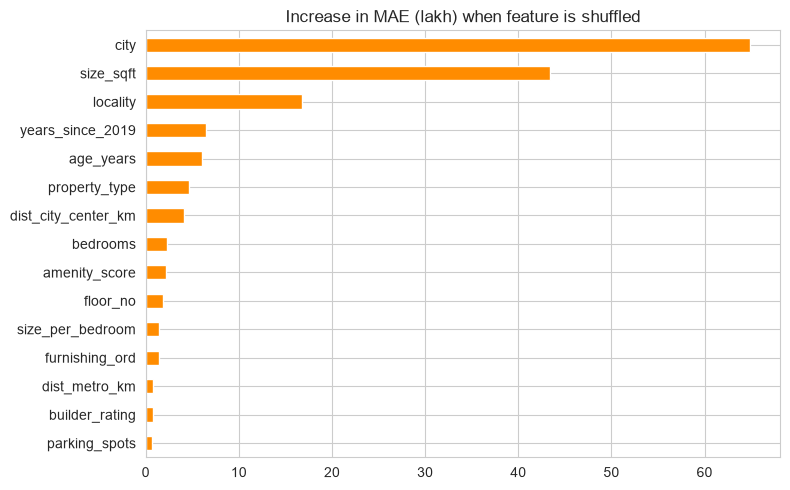

Top 5 drivers: ['city', 'size_sqft', 'locality', 'years_since_2019', 'age_years']
Near-zero importance (candidates to drop): ['bath_per_bed', 'floor_ratio', 'total_floors', 'gym_flag', 'security_flag', 'swimming_pool_flag', 'month', 'owner_type', 'is_new', 'rating_missing', 'facing', 'lift_flag', 'balconies']


In [33]:
Xs = X_test.sample(6000, random_state=1); ys = y_test.loc[Xs.index]
perm = permutation_importance(final_model, Xs, ys, n_repeats=3, scoring="neg_mean_absolute_error", random_state=1, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=Xs.columns).sort_values(ascending=False)
imp.head(15)[::-1].plot(kind="barh", figsize=(8, 5), color="darkorange", title="Increase in MAE (lakh) when feature is shuffled")
plt.tight_layout(); plt.show()
print("Top 5 drivers:", list(imp.index[:5]))
useless = imp[imp < imp.max() * 0.005].index.tolist()
print("Near-zero importance (candidates to drop):", useless)

# Part C: Classification

## Step 14: Will the house sell within 30 days? (`sold_within_30_days`)
**WHAT:** Binary classification.

**WHY:** Sellers care about speed. Here the asking price is a legitimate feature (it is known when the house is listed), so we add `price_lakh` and `price_per_sqft`. We still exclude `price_category` (derived from price, redundant).

**Metrics:** accuracy alone can mislead on imbalanced data, so we also use precision, recall, F1 and **ROC-AUC** (0.5 = coin flip, 1.0 = perfect).

In [34]:
df_fe["price_per_sqft"] = df_fe.price_lakh / df_fe.size_sqft
CLS_NUM = NUM + ["price_lakh", "price_per_sqft"]
Xc = df_fe[CLS_NUM + CAT]; yc = df_fe["sold_within_30_days"]
print("Class balance:"); print(yc.value_counts(normalize=True).round(3).to_string())

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=RANDOM_STATE, stratify=yc)
pre_c = ColumnTransformer([("num", StandardScaler(), CLS_NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
Xc_tr_a = pre_c.fit_transform(Xc_tr); Xc_te_a = pre_c.transform(Xc_te); cls_names = pre_c.get_feature_names_out()

clfs = {"Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=30, n_jobs=-1, class_weight="balanced", random_state=RANDOM_STATE),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=31, class_weight="balanced", n_jobs=-1, verbose=-1, random_state=RANDOM_STATE)}
crow, probs = [], {}
for n, m in clfs.items():
    m.fit(Xc_tr_a, yc_tr); pr = m.predict_proba(Xc_te_a)[:, 1]; pd_ = (pr >= .5).astype(int); probs[n] = pr
    crow.append(dict(Model=n, Accuracy=accuracy_score(yc_te, pd_), Precision=precision_score(yc_te, pd_), Recall=recall_score(yc_te, pd_),
                     F1=f1_score(yc_te, pd_), ROC_AUC=roc_auc_score(yc_te, pr)))
cres = pd.DataFrame(crow).set_index("Model").sort_values("ROC_AUC", ascending=False); cres

Class balance:
sold_within_30_days
0   0.64
1   0.36


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.67,0.53,0.80,0.64,0.77
LightGBM,0.67,0.53,0.81,0.64,0.77
Random Forest,0.66,0.52,0.83,0.64,0.77


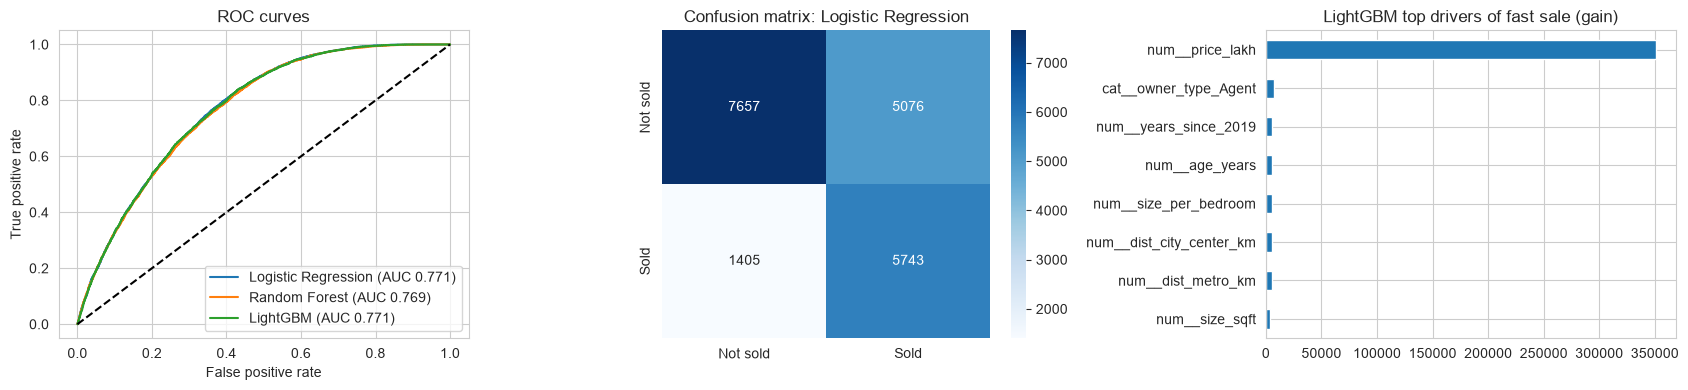

              precision    recall  f1-score   support

    Not sold       0.84      0.60      0.70     12733
        Sold       0.53      0.80      0.64      7148

    accuracy                           0.67     19881
   macro avg       0.69      0.70      0.67     19881
weighted avg       0.73      0.67      0.68     19881

→ Insight: strongest driver of quick sale = num__price_lakh.
→ Best AUC = 0.771. Selling speed has a big random component (buyer luck, negotiation), so a perfect score is impossible; this is realistic behaviour.


In [35]:
best_c = cres.index[0]; pr = probs[best_c]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for n, p in probs.items():
    f, t, _ = roc_curve(yc_te, p); ax[0].plot(f, t, label=f"{n} (AUC {roc_auc_score(yc_te,p):.3f})")
ax[0].plot([0,1],[0,1],"k--"); ax[0].legend(); ax[0].set_title("ROC curves"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
sns.heatmap(confusion_matrix(yc_te, (pr>=.5).astype(int)), annot=True, fmt="d", cmap="Blues", ax=ax[1],
            xticklabels=["Not sold","Sold"], yticklabels=["Not sold","Sold"]); ax[1].set_title(f"Confusion matrix: {best_c}")
m = clfs["LightGBM"]; gi = pd.Series(m.booster_.feature_importance("gain"), index=cls_names).sort_values(ascending=False).head(8)[::-1]
gi.plot(kind="barh", ax=ax[2], title="LightGBM top drivers of fast sale (gain)"); plt.tight_layout(); plt.show()
print(classification_report(yc_te, (pr>=.5).astype(int), target_names=["Not sold","Sold"]))
top_feat = gi.index[-1]
print(f"→ Insight: strongest driver of quick sale = {top_feat}.")
print(f"→ Best AUC = {cres.ROC_AUC.iloc[0]:.3f}. Selling speed has a big random component (buyer luck, negotiation), so a perfect score is impossible; this is realistic behaviour.")

In [36]:
cmp_ = df_fe.assign(sold=yc)
print("Sell-rate by owner type (%):");  print((cmp_.groupby("owner_type").sold.mean()*100).round(1).to_string())
print("\nSell-rate by price category (%):"); print((cmp_.groupby("price_category").sold.mean()*100).round(1).to_string())

Sell-rate by owner type (%):
owner_type
Agent     31.00
Builder   38.20
Owner     37.90

Sell-rate by price category (%):
price_category
Low      64.30
Medium   47.70
High     14.10


## Step 15: Predict the price *category* (Low / Medium / High)
**WHY:** A multi-class example. Here we must **exclude** price-based features (they would give the answer away).

Logistic Regression  accuracy = 0.939 | macro-F1 = 0.932
LightGBM             accuracy = 0.934 | macro-F1 = 0.926


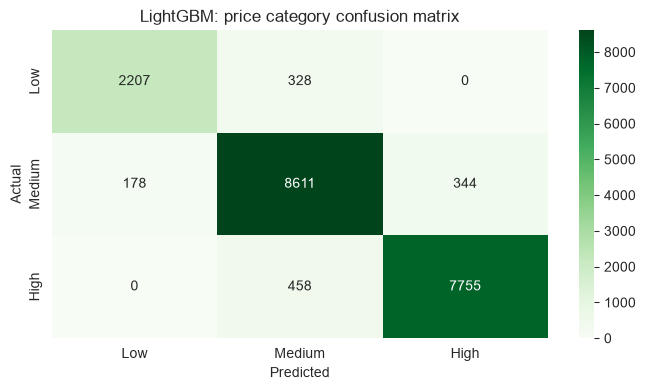

→ Insight: mistakes between neighbouring classes = 1308; Low↔High mistakes = 0. Errors sit at the class borders (e.g. a 49 vs 51 lakh house).


In [37]:
yk = df_fe["price_category"].astype(str)
Xk_tr, Xk_te, yk_tr, yk_te = train_test_split(X, yk, test_size=0.2, random_state=RANDOM_STATE, stratify=yk)
Xk_tr_a, Xk_te_a = pre.transform(Xk_tr), pre.transform(Xk_te)         # same preprocessing as regression
for n, m in {"Logistic Regression": LogisticRegression(max_iter=1000),
             "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE)}.items():
    m.fit(Xk_tr_a, yk_tr); pk = m.predict(Xk_te_a)
    print(f"{n:20s} accuracy = {accuracy_score(yk_te, pk):.3f} | macro-F1 = {f1_score(yk_te, pk, average='macro'):.3f}")
labels = ["Low","Medium","High"]
sns.heatmap(confusion_matrix(yk_te, pk, labels=labels), annot=True, fmt="d", cmap="Greens", xticklabels=labels, yticklabels=labels)
plt.title("LightGBM: price category confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()
cm = confusion_matrix(yk_te, pk, labels=labels); near = cm[0,1]+cm[1,0]+cm[1,2]+cm[2,1]; far = cm[0,2]+cm[2,0]
print(f"→ Insight: mistakes between neighbouring classes = {near}; Low↔High mistakes = {far}. Errors sit at the class borders (e.g. a 49 vs 51 lakh house).")

# Part D: Unsupervised learning

## Step 16: Market segments with K-Means + PCA
**WHAT:** Group houses by similarity *without using any target*.

**WHY:** Real businesses use segments ("budget small flats", "premium large homes") for marketing and pricing strategy. We pick the number of clusters `k` by the **silhouette score** (higher = better separated clusters). PCA squeezes the features to 2D so we can *see* the clusters.

In [38]:
cl_cols = ["size_sqft","price_per_sqft","age_years","dist_city_center_km","amenity_score","bedrooms"]
Z = df_fe[cl_cols].copy(); Z["size_sqft"] = np.log(Z.size_sqft); Z["price_per_sqft"] = np.log(Z.price_per_sqft)
Zs = StandardScaler().fit_transform(Z)
sil = {k: silhouette_score(Zs, KMeans(k, n_init=3, random_state=RANDOM_STATE).fit_predict(Zs), sample_size=6000, random_state=1) for k in range(2, 8)}
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})
k_best = max(sil, key=sil.get); print("Chosen k =", k_best)

Silhouette by k: {2: 0.187, 3: 0.154, 4: 0.172, 5: 0.159, 6: 0.164, 7: 0.153}
Chosen k = 2


         houses  median_price     size  ppsf_rs  age  dist_centre  amenities   top_city
segment                                                                                
0         40200        143.80 1,694.00 8,302.70 7.50         6.50       2.00  Bengaluru
1         59205         82.00 1,030.00 8,095.30 7.50         6.50       2.00  Bengaluru


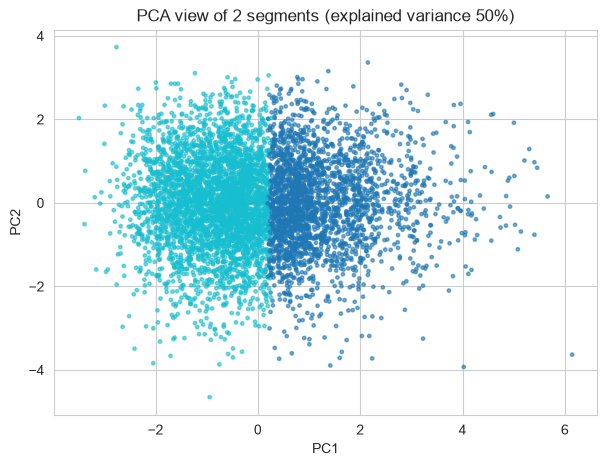

→ Insight: the clusters differ most on 'bedrooms' (then 'size_sqft'). Silhouette 0.19 is low: prices change smoothly, so there are no sharp natural groups.
  Treat segments as a convenient grouping for strategy, not as hard truth. Try k=4 or 5 if you want finer business segments.


In [39]:
km = KMeans(k_best, n_init=5, random_state=RANDOM_STATE).fit(Zs)
df_fe["segment"] = km.labels_
prof = df_fe.groupby("segment").agg(houses=("price_lakh","size"), median_price=("price_lakh","median"), size=("size_sqft","median"),
        ppsf_rs=("price_per_sqft", lambda s: s.median()*1e5), age=("age_years","median"), dist_centre=("dist_city_center_km","median"),
        amenities=("amenity_score","median"), top_city=("city", lambda s: s.mode()[0]))
print(prof.round(1).to_string())

p2 = PCA(2, random_state=0); P = p2.fit_transform(Zs); ii = np.random.RandomState(2).choice(len(P), 6000, replace=False)
plt.figure(figsize=(7, 5)); plt.scatter(P[ii,0], P[ii,1], c=km.labels_[ii], cmap="tab10", s=6, alpha=.6)
plt.title(f"PCA view of {k_best} segments (explained variance {p2.explained_variance_ratio_.sum()*100:.0f}%)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()
cent = pd.DataFrame(km.cluster_centers_, columns=cl_cols); spread = (cent.max() - cent.min()).sort_values(ascending=False)
print(f"→ Insight: the clusters differ most on '{spread.index[0]}' (then '{spread.index[1]}'). Silhouette {sil[k_best]:.2f} is low: prices change smoothly, so there are no sharp natural groups.")
print("  Treat segments as a convenient grouping for strategy, not as hard truth. Try k=4 or 5 if you want finer business segments.")

# Part E: Time series

## Step 17: Price-index forecasting
**WHAT:** Build a monthly **market price index**, then forecast the next months.

**WHY:** Cities have different price levels, so we divide each house's price per sq.ft by its city median first (index ≈ 1.0 = typical level). The monthly median of that is a clean time series.

**Fair comparison:** hold out the **last 12 months** as test. A model is only useful if it beats the *naive* guess (“next month = last month”).

Months: 84 | 2019-01-01 → 2025-12-01


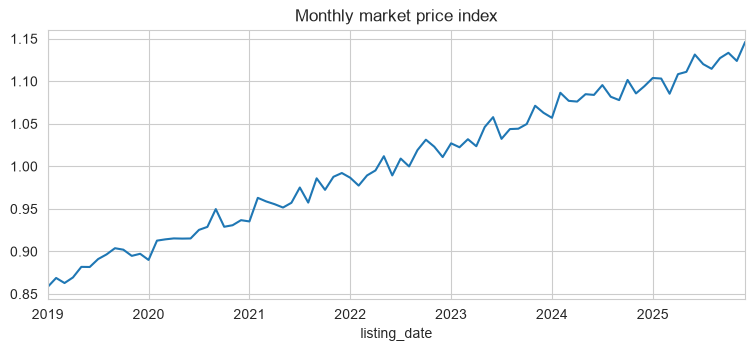

In [40]:
df_fe["ppsf_index"] = df_fe.price_per_sqft / df_fe.groupby("city").price_per_sqft.transform("median")
ts = df_fe.set_index("listing_date")["ppsf_index"].resample("MS").median().dropna()
print("Months:", len(ts), "|", ts.index.min().date(), "→", ts.index.max().date())
ts.plot(figsize=(9,3.5), title="Monthly market price index"); plt.show()

C:\Users\SASWAT\.conda\envs\notebook-env\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                       MAE  MAPE
ARIMA(1,1,1)+drift    0.01  0.76
Holt (exp. smoothing) 0.01  0.76
Naive (last value)    0.02  2.19


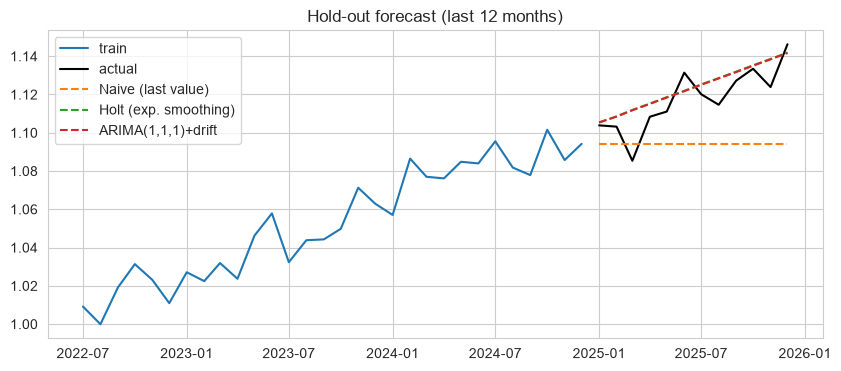

→ Insight: best = ARIMA(1,1,1)+drift. Models with a trend term beat the naive guess because prices rise steadily over time.


In [41]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
H = 12; tr_ts, te_ts = ts.iloc[:-H], ts.iloc[-H:]
fc = {"Naive (last value)": pd.Series(tr_ts.iloc[-1], index=te_ts.index)}
fc["Holt (exp. smoothing)"] = ExponentialSmoothing(tr_ts, trend="add").fit().forecast(H)
fc["ARIMA(1,1,1)+drift"]    = ARIMA(tr_ts, order=(1,1,1), trend="t").fit().forecast(H)
tsr = pd.DataFrame({n: dict(MAE=mean_absolute_error(te_ts, f), MAPE=np.mean(np.abs((te_ts-f)/te_ts))*100) for n, f in fc.items()}).T.sort_values("MAE")
print(tsr.round(4).to_string())

plt.figure(figsize=(10, 4)); plt.plot(tr_ts.index[-30:], tr_ts.iloc[-30:], label="train"); plt.plot(te_ts.index, te_ts, "k", label="actual")
for n, f in fc.items(): plt.plot(f.index, f, "--", label=n)
plt.legend(); plt.title("Hold-out forecast (last 12 months)"); plt.show()
print(f"→ Insight: best = {tsr.index[0]}. Models with a trend term beat the naive guess because prices rise steadily over time.")

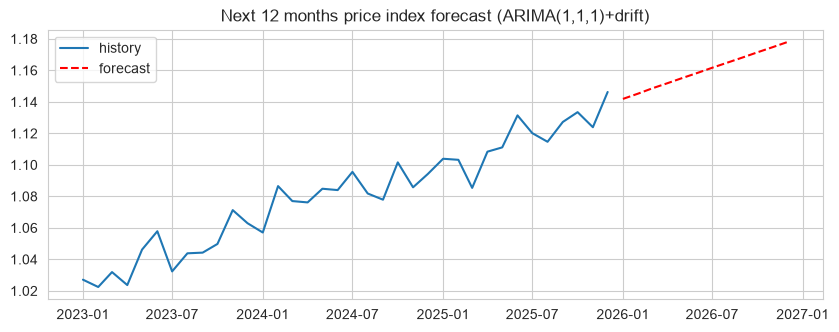

Forecast: index 1.146 now → 1.178 in 12 months (+2.8%)


In [42]:
best_ts = tsr.index[0]
final_ts = ARIMA(ts, order=(1,1,1), trend="t").fit() if "ARIMA" in best_ts else ExponentialSmoothing(ts, trend="add").fit()
future = final_ts.forecast(12)
plt.figure(figsize=(10, 3.5)); plt.plot(ts.index[-36:], ts.iloc[-36:], label="history"); plt.plot(future.index, future, "r--", label="forecast")
plt.legend(); plt.title(f"Next 12 months price index forecast ({best_ts})"); plt.show()
print(f"Forecast: index {ts.iloc[-1]:.3f} now → {future.iloc[-1]:.3f} in 12 months ({(future.iloc[-1]/ts.iloc[-1]-1)*100:+.1f}%)")

# Part F: Deployment

## Step 18: Retrain on all data and save
**WHY:** After choosing the model with the test set, the final model should learn from *every* row (more data = better). We save the **whole pipeline** (preprocessing + model + log transform) so new data is handled identically.

In [43]:
final_model.fit(X, y)
joblib.dump(final_model, "house_price_model.pkl")
print("Saved house_price_model.pkl")

Saved house_price_model.pkl


## Step 19: Prediction function for new houses
**WHY:** Wrap everything so you only supply raw inputs. The same `build_features()` is reused, so training and prediction can never disagree.

In [44]:
model = joblib.load("house_price_model.pkl")

def predict_price(city, locality, property_type, size_sqft, bedrooms, bathrooms=None, balconies=1, floor_no=2, total_floors=5,
                  age_years=5, furnishing="Semi-Furnished", parking_spots=1, lift="Yes", gym="No", swimming_pool="No",
                  security="Yes", dist_city_center_km=6, dist_metro_km=3, facing="East", owner_type="Owner",
                  builder_rating=3.8, listing_date="2025-01-01"):
    row = pd.DataFrame([dict(city=city, locality=locality, property_type=property_type, size_sqft=size_sqft, bedrooms=bedrooms,
        bathrooms=bathrooms or bedrooms, balconies=balconies, floor_no=floor_no, total_floors=total_floors, age_years=age_years,
        furnishing=furnishing, parking_spots=parking_spots, lift=lift, gym=gym, swimming_pool=swimming_pool, security=security,
        dist_city_center_km=dist_city_center_km, dist_metro_km=dist_metro_km, facing=facing, owner_type=owner_type,
        builder_rating=builder_rating, rating_missing=0, listing_date=listing_date)])
    return float(model.predict(build_features(row)[NUM + CAT])[0])

print(f"Cuttack, CDA, 1200 sqft 3BHK flat      → ₹{predict_price('Cuttack','CDA','Apartment',1200,3):,.1f} lakh")
print(f"Mumbai, Powai, 1200 sqft 3BHK flat     → ₹{predict_price('Mumbai','Powai','Apartment',1200,3):,.1f} lakh")
print(f"Bhubaneswar, Patia, 1800 sqft villa    → ₹{predict_price('Bhubaneswar','Patia','Villa',1800,4,total_floors=2,floor_no=0,lift='No',age_years=2):,.1f} lakh")
print(f"Same Cuttack flat, 20 years old        → ₹{predict_price('Cuttack','CDA','Apartment',1200,3,age_years=20):,.1f} lakh")
print(f"Same Cuttack flat + gym + pool         → ₹{predict_price('Cuttack','CDA','Apartment',1200,3,gym='Yes',swimming_pool='Yes'):,.1f} lakh")

Cuttack, CDA, 1200 sqft 3BHK flat      → ₹61.6 lakh
Mumbai, Powai, 1200 sqft 3BHK flat     → ₹361.3 lakh
Bhubaneswar, Patia, 1800 sqft villa    → ₹148.2 lakh
Same Cuttack flat, 20 years old        → ₹51.6 lakh
Same Cuttack flat + gym + pool         → ₹68.8 lakh


## Step 20: Final scoreboard

In [45]:
print("=" * 60)
print(f"REGRESSION  best single model : {results.index[0]}  (MAPE {results.MAPE.iloc[0]:.2f}%, R² {results.R2.iloc[0]:.4f})")
print(f"            tuned LightGBM    : MAPE {rt['MAPE']:.2f}%")
print(f"            final CV R²       : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"CLASSIFY    sold in 30 days   : best {cres.index[0]}, ROC-AUC {cres.ROC_AUC.iloc[0]:.3f}")
print(f"CLUSTERING  market segments   : k = {k_best}")
print(f"TIME SERIES best forecaster   : {tsr.index[0]}  (MAPE {tsr.MAPE.iloc[0]:.2f}%)")
print("=" * 60)

REGRESSION  best single model : CatBoost  (MAPE 6.22%, R² 0.9844)
            tuned LightGBM    : MAPE 6.48%
            final CV R²       : 0.9801 ± 0.0005
CLASSIFY    sold in 30 days   : best Logistic Regression, ROC-AUC 0.771
CLUSTERING  market segments   : k = 2
TIME SERIES best forecaster   : ARIMA(1,1,1)+drift  (MAPE 0.76%)


## Step 21: Limitations and next steps (honest notes)
- **Synthetic data:** patterns are cleaner than real life. Real data has noisier relationships, so expect lower scores.
- **Random split:** for a live system, validate with a *time-based* split (train on past years, test on the latest year), because the model will predict the future.
- **Selling speed** is inherently noisy; treat the probability as guidance, not a guarantee.
- **Next steps:** add real features (nearby schools, hospitals, GPS), try target encoding for `locality`, add SHAP explanations, deploy with FastAPI/Streamlit, and monitor drift (price levels move ~4–5% a year, so retrain regularly).

In [46]:
import os
print("File saved at:", os.path.abspath("all_models_metrics.csv"))

File saved at: C:\Users\SASWAT\AppData\Local\Programs\anaconda-desktop\all_models_metrics.csv


In [47]:
import os
print("Zip file location:", os.path.abspath("all_models_exported.zip"))

Zip file location: C:\Users\SASWAT\AppData\Local\Programs\anaconda-desktop\all_models_exported.zip
